# Polishing errors: figure, mid-spatial frequencies and the edge

A lens is only as good as its polished surfaces. The design of an asphere
may be perfect, but the shop delivers it with errors on every lateral
scale, and the scales matter in different ways (ISO 10110-5 and -8;
Aikens, Wolfe and Lawson):

- **figure** (a few cycles over the aperture) is a wavefront aberration: it
  lowers the Strehl ratio and blurs the core of the PSF;
- **mid-spatial frequencies** (MSF, periods of a fraction of a millimetre to
  a few millimetres) are the fingerprint of the small tools that polish
  aspheres. A periodic ripple diffracts like a weak phase grating: it puts
  ghost images, rings and a halo next to the PSF and lowers the MTF at all
  but the lowest frequencies, while the Strehl ratio hardly moves
  (Youngworth and Stone; Tamkin and Milster);
- **roughness** (shorter periods) scatters into wide angles, out of the
  image: it is a loss of power, not an aberration.

`raytrace.ZernikeSurface` covers smooth figure errors. Polishing errors
need more: an arbitrary map, measured by an interferometer pixel by pixel or
simulated, interpolated between the pixels, with slopes that refract the
rays correctly. This notebook introduces

- `raytrace.SurfaceMap`: a function of the surface coordinates on a grid,
  interpolated (nearest pixel, bilinear, cubic or quintic splines) with
  analytic gradients and Hessians,
- `raytrace.MapSurface`: a surface whose sag departs from its base by such a
  map (and optionally by Zernike terms), traced exactly with the normals of
  the interpolant,
- ``energy_map`` on any surface: a map of the transmitted (or, on a mirror,
  reflected) power fraction, which becomes the pupil apodization of the
  PSF and enters the polarization ray trace,
- `pyoptics.polishing`: the errors themselves, the ripple of raster and
  spiral tool paths, the turned-down edge, random figure with a power law
  PSD, the specular loss of roughness and pixelated digs and scratches.

The test piece is a fast plano-convex asphere: it is the kind of surface
that has to be polished with sub-aperture tools, and it is free of
aberrations by design, so everything we see below comes from the
polishing.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from numpy import pi

from pyoptics import polishing as po
from pyoptics import sketch
from pyoptics.raytrace import MapSurface, SurfaceMap, hyperbolic_lens

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
T_START = time.time()

## 0. How aspheres are polished

A sphere fits its tool everywhere: a full-aperture lap of the same radius
rubs over the whole surface and smooths it on all scales. An asphere
changes its curvature from the centre to the rim, so a large tool does
not fit. It is polished with a small tool instead (a precessed bonnet, a
pitch tool on a CNC machine, magnetorheological finishing) that removes
material in a spot of a few millimetres. By Preston's law the removal is
proportional to the pressure, the relative speed and the dwell time, so the
removal profile of the spot (the **tool influence function**, TIF) is a
fixed shape, and the machine writes the wanted removal map by moving the
spot along a tool path and varying its speed.

Neighbouring tracks of a raster or spiral path overlap. Their sum is a
mean removal plus a ripple with the period of the path, the pitch $p$. For
a Gaussian TIF of width $s$ across the track, the Poisson sum gives the
ripple exactly:

$$\sum_k g(u - kp) = \frac{D}{p}\Bigl[1 + 2\sum_{m\ge 1} e^{-2\pi^2 m^2 s^2/p^2}\cos\frac{2\pi m u}{p}\Bigr],$$

so the ripple amplitude falls off like a Gaussian in $s/p$: a tool that is
wider than the pitch leaves almost nothing, a tool that is narrower leaves a
corrugated surface (`polishing.tool_path_ripple()`). At the rim the tool
overhangs the part, the remaining contact area carries the whole load, the
pressure rises and the edge is turned down (Kim, Park, Kim and Burge).

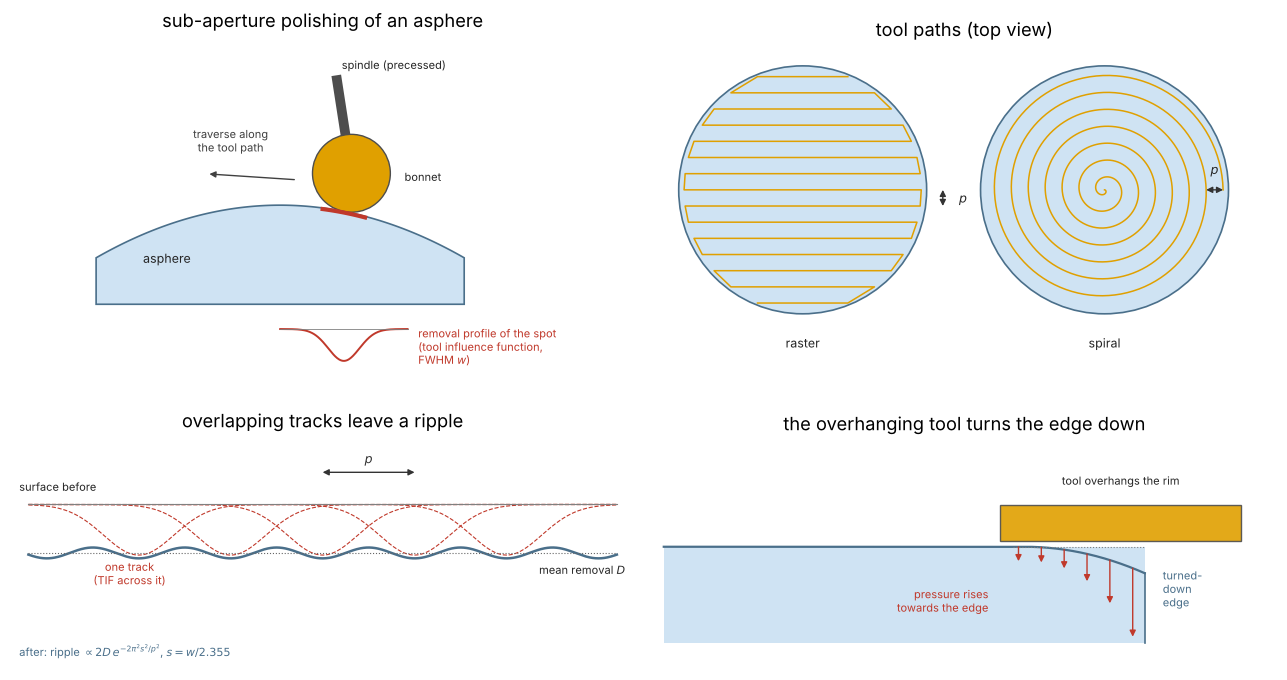

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
sketch.polishing_layout(axes[0, 0], "tool", title="sub-aperture polishing of an asphere")
sketch.polishing_layout(axes[0, 1], "paths", title="tool paths (top view)")
sketch.polishing_layout(axes[1, 0], "ripple", title="overlapping tracks leave a ripple")
sketch.polishing_layout(axes[1, 1], "edge", title="the overhanging tool turns the edge down")
plt.tight_layout()

## 1. The lens

`raytrace.hyperbolic_lens()` is a plano-convex lens whose back surface is a
hyperboloid with $K = -n^2$: a collimated beam that enters through the flat
side is focused without any aberration, a laser focusing or condenser
asphere. We take 25 mm diameter, a back focal length of 30 mm (NA 0.385)
and N-BK7 at 632.8 nm. The flat face is easy to polish to perfection; all
errors go onto the asphere, surface 1 of the system.

All maps live on one grid of 0.05 mm over the asphere, fine enough to
resolve the shortest ripple below with 20 samples per period.

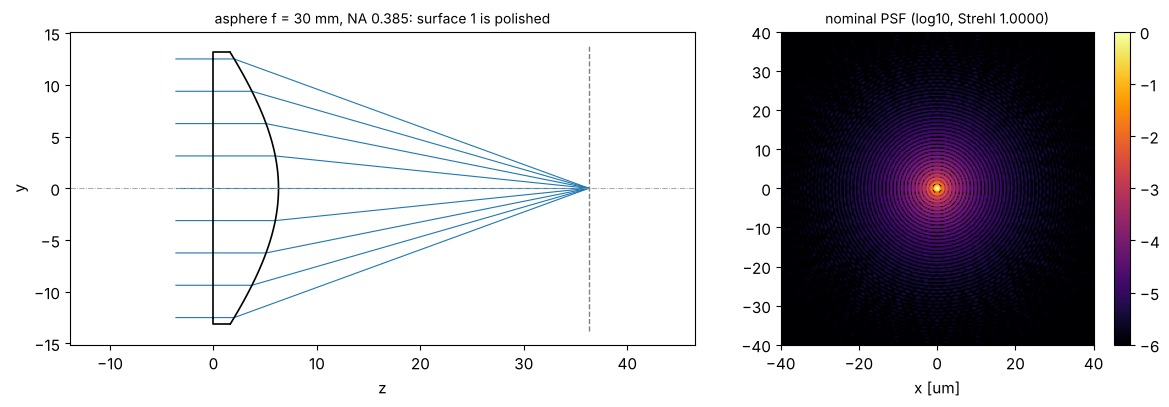

In [3]:
WL = 632.8e-6                    # mm
A, F, N_BK7 = 12.5, 30.0, 1.51509
lens = hyperbolic_lens(A, F, n=N_BK7, wavelength=WL)
NA = A/np.hypot(A, F)

xg = np.linspace(-13.0, 13.0, 521)       # map grid on the asphere [mm]
XG, YG = np.meshgrid(xg, xg)
RG = np.hypot(XG, YG)


def polished(dz=None, energy=None, kind="cubic", grid=(xg, xg), base=lens):
    # The lens with the sag departure dz (mm, sampled on grid) on the asphere
    # and optional energy maps {surface: SurfaceMap}.
    S = base.copy()
    s = S.surfaces[1]
    if dz is not None:
        S.surfaces[1] = MapSurface(s.R, s.thickness, sag_map=SurfaceMap(*grid, dz, kind=kind),
                                   n_after=1.0, conic=s.conic)
    for i, m in (energy or {}).items():
        S.surfaces[i].energy_map = m
    return S


# image window: +-80 um, fine enough for the Airy disk (radius 1.0 um),
# wide enough for ghosts 20 um away
L_IMG = 0.16
xi = np.linspace(-L_IMG/2, L_IMG/2, 512, endpoint=False)
N_PUPIL = 241                    # rays across the pupil (>= 8 per ripple period)


def psf(S, N=N_PUPIL):
    return np.abs(S.psf(xi, xi, 0.0, N=N))**2


def show_psf(ax, I, title, half=40.0, vmin=-6, vmax=0):
    ext = 1e3*np.array([xi[0], xi[-1], xi[0], xi[-1]])
    im = ax.imshow(np.log10(np.maximum(I, 10**vmin)), extent=ext, origin="lower", cmap="inferno",
                   vmin=vmin, vmax=vmax)
    ax.set_xlim(-half, half)
    ax.set_ylim(-half, half)
    ax.set_xlabel("x [um]")
    ax.set_title(title, fontsize=10)
    return im


I_nominal = psf(lens)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
lens.draw(axes[0], fields=[0.0], n_rays=9)
axes[0].set_title("asphere f = 30 mm, NA {:.3f}: surface 1 is polished".format(NA), fontsize=10)
im = show_psf(axes[1], I_nominal, "nominal PSF (log10, Strehl {:.4f})".format(lens.strehl(0.0, N=N_PUPIL)))
plt.colorbar(im, ax=axes[1])
plt.tight_layout()

The nominal lens is perfect; the PSF is the Airy pattern of NA 0.385 with
its rings falling to $10^{-5}$ at the edge of the plot. The colour scale
spans six decades, because that is where polishing errors show first.

## 2. Gridded maps in the ray trace

A surface map in pyoptics is a `SurfaceMap`: samples `values[i, j]` at
`(x[j], y[i])` in the local frame of the surface, the convention of an
image. `MapSurface` adds it to the sag of a base surface (sphere, conic,
asphere) and to optional Zernike terms. Rays are intersected by Newton steps
on the full sag and refracted with the normals of the interpolant, so the
map acts with its slopes, not only with its height.

That makes the interpolation part of the physics. A measured map is a grid
of pixels, here simulated: a random figure with a power law PSD, sampled by
an interferometer with 0.8 mm pixels (33 pixels across the lens). Three
ways to put it into the lens:

- `kind="nearest"`: pixels as flat terraces. The height is right, but the
  slopes are zero within a pixel and infinite between them; useless for a
  sag, fine for an energy map.
- `kind="linear"`: bilinear. The surface is continuous, but its slopes jump
  at every pixel border, so the lens is a mosaic of small facets.
- `kind="cubic"` (the default): a smooth spline through the samples.

The truth is the same random surface on the fine grid. The figure holds
periods down to 3.3 mm, so the pixels sample it four times per period; the
spot diagrams trace the same 11 000 rays through each version.

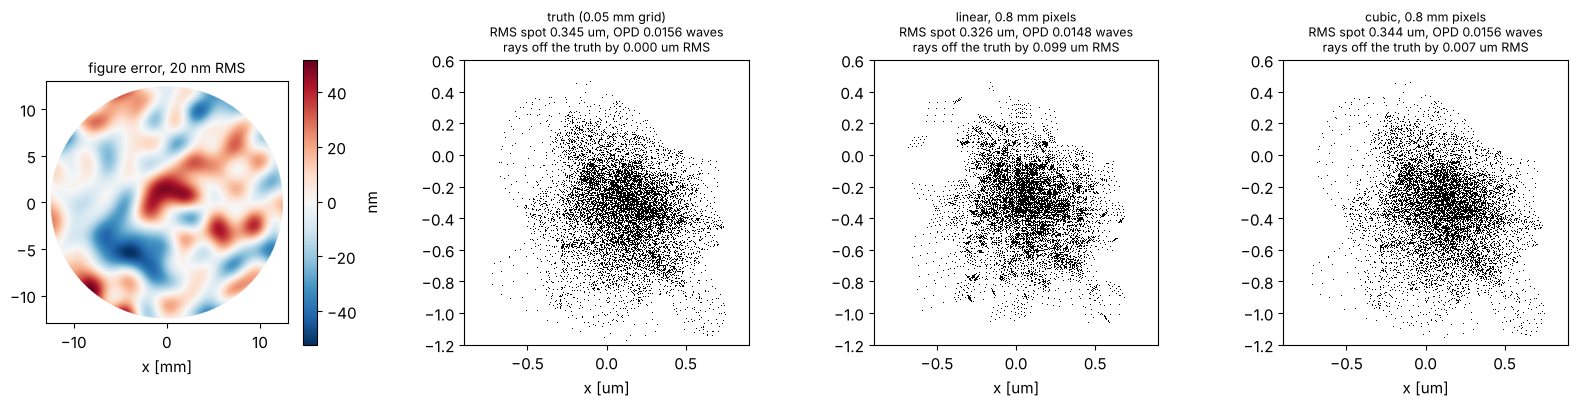

In [4]:
psd_figure = lambda f: po.psd_power_law(f, 1.0, 2.5, f_min=1/26, f_max=0.3)
fine = po.random_surface(xg, xg, psd_figure, rms=20e-6, seed=7)    # 20 nm RMS, periods > 3 mm
step = 16                                                           # 0.8 mm pixels
xm = xg[::step]
measured = fine[::step, ::step]

variants = {"truth (0.05 mm grid)": polished(fine),
            "linear, 0.8 mm pixels": polished(measured, kind="linear", grid=(xm, xm)),
            "cubic, 0.8 mm pixels": polished(measured, kind="cubic", grid=(xm, xm))}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
im = axes[0].imshow(1e6*np.where(RG <= A, fine, np.nan), extent=[xg[0], xg[-1], xg[0], xg[-1]],
                    origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[0], label="nm")
axes[0].set_title("figure error, 20 nm RMS", fontsize=10)
axes[0].set_xlabel("x [mm]")
spots = {name: S.spot_diagram(0.0, N=121) for name, S in variants.items()}
truth = spots["truth (0.05 mm grid)"]
for ax, (name, sd) in zip(axes[1:], spots.items()):
    dev = 1e3*np.sqrt(np.mean((sd.x - truth.x)**2 + (sd.y - truth.y)**2))
    ax.plot(1e3*sd.x, 1e3*sd.y, ",", color="k")
    ax.set_aspect("equal")
    ax.set_xlim(-0.9, 0.9)
    ax.set_ylim(-1.2, 0.6)
    ax.set_xlabel("x [um]")
    ax.set_title("{}\nRMS spot {:.3f} um, OPD {:.4f} waves\nrays off the truth by {:.3f} um RMS".format(
        name, 1e3*sd.rms, variants[name].rms_opd(0.0, N=121), dev), fontsize=9)
plt.tight_layout()

All three agree in the wavefront: the OPD is an integral of the height,
and the heights are right at every pixel. The rays tell them apart. With
the bilinear map every ray is refracted by the slope of its facet, the
spot diagram breaks up into small clusters and streaks, and the rays land
0.1 um RMS away from where the true surface sends them, a third of the
spot size. The cubic spline puts them within 0.007 um. For sag maps, use a
spline; bilinear and nearest pixel interpolation are for energy maps.
A spline cannot invent what the pixels do not resolve, though: the grid of a
map must sample its shortest period several times, and the pupil sampling
`N` of `opd()`, `pupil()` and `psf()` must resolve its image in the pupil.

## 3. The turned-down edge

The first error to check on any polished part is the edge. A roll-off that
starts at 80 % of the radius and reaches a depth $d$ at the rim
(`polishing.turned_down_edge()`, quadratic here) bends the marginal rays
inwards, like spherical aberration of very high order confined to the
outer zone.

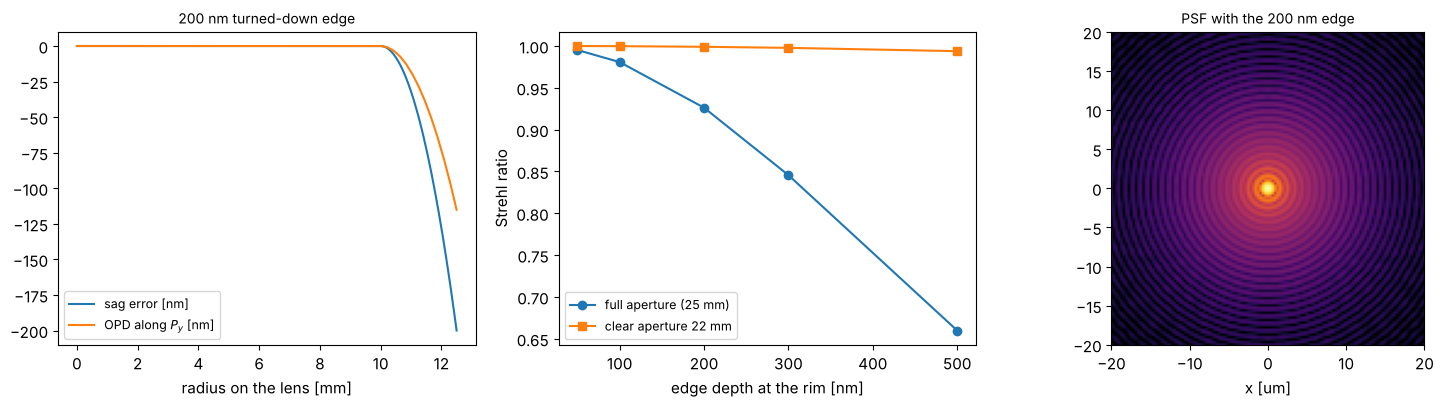

In [5]:
depths = np.array([0.05, 0.1, 0.2, 0.3, 0.5])*1e-3    # mm
strehl_edge, strehl_stopped = [], []
for d in depths:
    S = polished(po.turned_down_edge(XG, YG, 10.0, A, d))
    strehl_edge.append(S.strehl(0.0, N=161))
    S.surfaces[0].semi_diameter = 11.0                 # clear aperture reduced to 22 mm
    strehl_stopped.append(S.strehl(0.0, N=161))

TDE = 0.2e-3
S_edge = polished(po.turned_down_edge(XG, YG, 10.0, A, TDE))
W = S_edge.opd(0.0, N=121)
I_edge = psf(S_edge)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
r = np.linspace(0, A, 300)
axes[0].plot(r, 1e6*po.turned_down_edge(r, 0*r, 10.0, A, TDE), label="sag error [nm]")
axes[0].plot(W.py[W.py >= 0]*A, W.W[W.py >= 0, len(W.px)//2]*WL*1e6, label="OPD along $P_y$ [nm]")
axes[0].set_xlabel("radius on the lens [mm]")
axes[0].legend(fontsize=9)
axes[0].set_title("{:.0f} nm turned-down edge".format(1e6*TDE), fontsize=10)
axes[1].plot(1e6*depths, strehl_edge, "o-", label="full aperture (25 mm)")
axes[1].plot(1e6*depths, strehl_stopped, "s-", label="clear aperture 22 mm")
axes[1].set_xlabel("edge depth at the rim [nm]")
axes[1].set_ylabel("Strehl ratio")
axes[1].legend(fontsize=9)
show_psf(axes[2], I_edge, "PSF with the {:.0f} nm edge".format(1e6*TDE), half=20)
plt.tight_layout()

The OPD follows the sag scaled by about $n - 1$ (a little more at the
rim, where the rays leave the steep asphere obliquely). The Strehl ratio
falls quickly with the depth, because the error sits in the outer zone,
which carries the largest share of the pupil area: 200 nm at the rim,
a third of a wave of sag, cost 7 %, 500 nm a third of the peak. The light
goes into the rings of the PSF. Specifying a clear aperture of 22 mm
instead of 25 mm (or stopping the beam down) hides the edge almost
completely, which is why drawings give the edge zone its own tolerance or
exclude it.

## 4. Mid-spatial frequencies: the ripple of the tool path

Now a smooth figure and a perfect edge, but a tool of 0.9 mm FWHM driven
on a 1 mm raster and removing 200 nm on average: the residual ripple has an
amplitude of 22 nm (`polishing.ripple_amplitude()`). Behind the
asphere it is a phase grating with the phase amplitude
$\beta \approx 2\pi(n - 1)a/\lambda$. A sinusoidal phase grating diffracts
into the orders $m$ with the amplitudes $J_m(\beta)$, so each first order
carries $J_1^2/J_0^2 \approx \beta^2/4$ of the power of the image, and it
lands at the distance $f\lambda/p$ from it.

A spiral path has the same profile across the tracks, but the tracks are
rings: the ghosts become a ring of the same radius around the PSF.

ghost power 3.01e-03 of the image, beta**2/4 = 3.27e-03; at 19.1 um, f lambda/p = 19.0 um


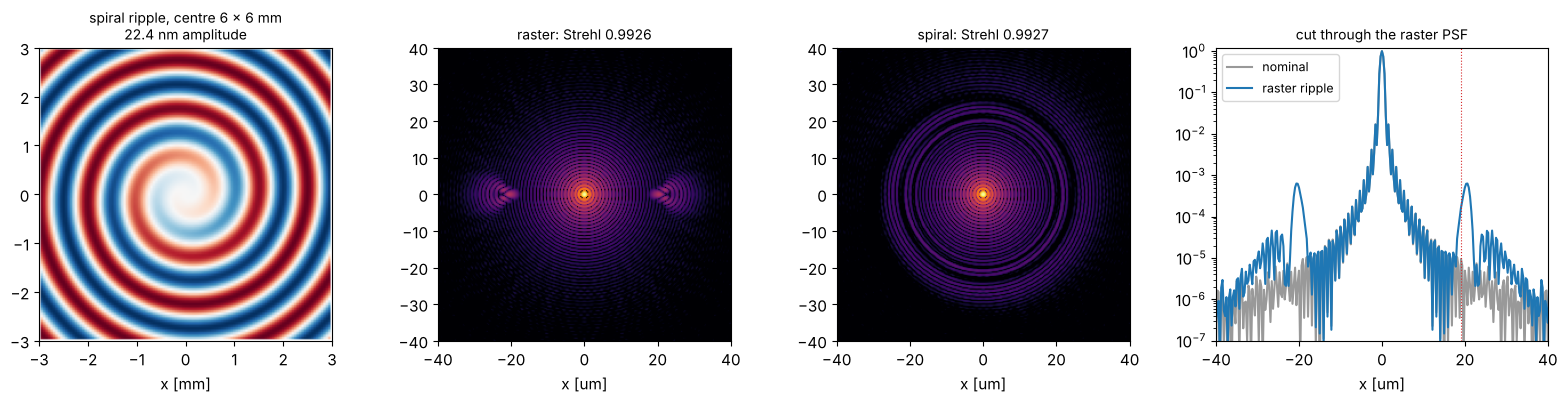

In [6]:
P_TOOL, W_TOOL, REMOVAL = 1.0, 0.9, 200e-6
amp = po.ripple_amplitude(P_TOOL, W_TOOL, REMOVAL)
raster = po.tool_path_ripple(XG, YG, P_TOOL, W_TOOL, REMOVAL, path="raster")
spiral = po.tool_path_ripple(XG, YG, P_TOOL, W_TOOL, REMOVAL, path="spiral")
S_raster, S_spiral = polished(raster), polished(spiral)
I_raster, I_spiral = psf(S_raster), psf(S_spiral)

beta = 2*pi*(N_BK7 - 1)*amp/WL
x_ghost = F*WL/P_TOOL
c = len(xi)//2
k = np.argmin(np.abs(xi - x_ghost))
h = 26                      # +-8 um around the ghost and around the image
ghost = ((I_raster - I_nominal)[c - h:c + h + 1, k - h:k + h + 1].sum()
         / I_nominal[c - h:c + h + 1, c - h:c + h + 1].sum())

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(1e6*np.where((np.abs(XG) < 3) & (np.abs(YG) < 3), spiral, np.nan),
               extent=[xg[0], xg[-1], xg[0], xg[-1]], origin="lower", cmap="RdBu_r")
axes[0].set_xlim(-3, 3)
axes[0].set_ylim(-3, 3)
axes[0].set_title("spiral ripple, centre 6 x 6 mm\n{:.1f} nm amplitude".format(1e6*amp), fontsize=10)
axes[0].set_xlabel("x [mm]")
show_psf(axes[1], I_raster, "raster: Strehl {:.4f}".format(S_raster.strehl(0.0, N=N_PUPIL)))
show_psf(axes[2], I_spiral, "spiral: Strehl {:.4f}".format(S_spiral.strehl(0.0, N=N_PUPIL)))
axes[3].semilogy(1e3*xi, I_nominal[c], color="0.6", label="nominal")
axes[3].semilogy(1e3*xi, I_raster[c], label="raster ripple")
axes[3].axvline(1e3*x_ghost, color="C3", lw=0.8, ls=":")
axes[3].set_xlim(-40, 40)
axes[3].set_ylim(1e-7, 1.2)
axes[3].set_xlabel("x [um]")
axes[3].legend(fontsize=9)
axes[3].set_title("cut through the raster PSF", fontsize=10)
plt.tight_layout()
print("ghost power {:.2e} of the image, beta**2/4 = {:.2e}; at {:.1f} um, f lambda/p = {:.1f} um".format(
    ghost, beta**2/4, 1e3*xi[k], 1e3*x_ghost))

The raster ghosts sit at $f\lambda/p$ = 19 um on both sides of the image,
in the direction across the tracks, and each carries $3.0\cdot10^{-3}$ of
the power of the image, close to $\beta^2/4 = 3.3\cdot10^{-3}$ with
$\beta = 0.115$ rad. They are blurred into small arcs, since the ripple
period seen by the rays changes over the strongly curved surface. The
spiral path makes a ring of the same radius instead. Both leave the Strehl
ratio at 0.993: by the usual figure specifications this lens is perfect,
yet a laser focus or a high dynamic range image shows ghosts of a few
$10^{-3}$ next to every bright point.

### The MTF

The PSF of a laser focus shows the ghosts; for an imaging lens they turn
into a loss of contrast. The OTF is the autocorrelation of the pupil: for
a pupil phase $\beta\cos(2\pi u/p)$, two copies of the pupil shifted by
$\Delta$ multiply with the phase difference
$2\beta\sin(\pi\Delta/p)\sin(\dots)$, and the MTF is multiplied by
$J_0\bigl(2\beta\sin(\pi\Delta/p)\bigr)$ (Tamkin and Milster). The factor
drops from 1 at zero shift to about $1 - \beta^2$ at half a period and
then oscillates about $J_0(\beta)^2 \approx 1 - \beta^2/2$ for all larger
shifts. In image space the shift of half a ripple period is the frequency $\nu = 1/(2\lambda f/p)$, only
26 cycles/mm for this lens, far below its cutoff $2\,\mathrm{NA}/\lambda$
= 1216 cycles/mm. A ripple of a few nanometres lowers the MTF
uniformly over almost the whole passband, a "shelf" that no focus
adjustment removes (Youngworth and Stone).

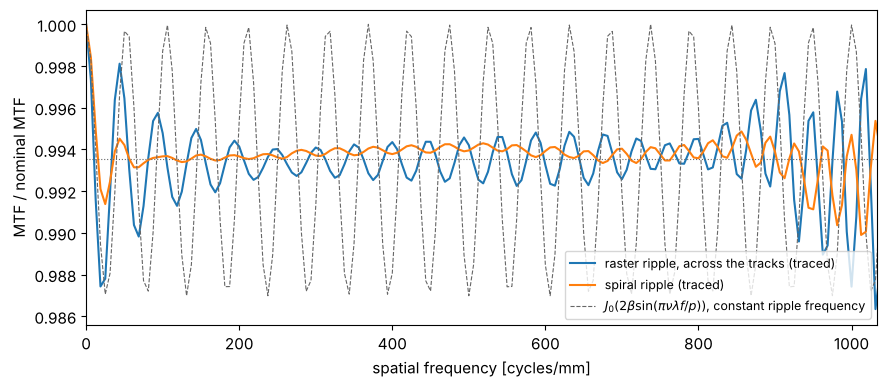

In [7]:
def mtf_x(I):
    otf = np.fft.fft2(np.fft.ifftshift(I))
    return np.abs(otf[0, :len(xi)//2])/np.abs(otf[0, 0])


nu = np.fft.fftfreq(len(xi), xi[1] - xi[0])[:len(xi)//2]
cutoff = 2*NA/WL
m0, m_raster, m_spiral = mtf_x(I_nominal), mtf_x(I_raster), mtf_x(I_spiral)
nu_half = P_TOOL/(2*WL*F)

fig, ax = plt.subplots(figsize=(9, 4))
ok = m0 > 1e-3
ax.plot(nu[ok], m_raster[ok]/m0[ok], label="raster ripple, across the tracks (traced)")
ax.plot(nu[ok], m_spiral[ok]/m0[ok], label="spiral ripple (traced)")
theory = np.abs(np.array([np.mean(np.cos(2*beta*np.sin(pi*n*WL*F/P_TOOL)
                                         *np.sin(np.linspace(0, 2*pi, 400)))) for n in nu]))
ax.plot(nu[ok], theory[ok], "--", color="0.4", lw=0.8,
        label=r"$J_0(2\beta\sin(\pi\nu\lambda f/p))$, constant ripple frequency")
ax.axhline(np.mean(theory), color="0.4", lw=0.8, ls=":")
ax.set_xlim(0, 0.85*cutoff)
ax.set_xlabel("spatial frequency [cycles/mm]")
ax.set_ylabel("MTF / nominal MTF")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()

Across the raster tracks, the MTF ratio drops within the first 26
cycles/mm and then oscillates about the shelf $J_0(\beta)^2 \approx
1 - \beta^2/2 = 0.9935$ (dotted). The oscillation is weaker than for a ripple
of constant frequency (dashed): the ripple period in the pupil, measured in
image space direction sines, changes from the centre to the rim of this
fast lens, which smears the phases of the oscillation. The spiral ripple,
with no preferred direction, gives the shelf with hardly any oscillation.
A loss of 0.7 % is harmless here; with an amplitude of 100 nm (pitch 1.4 mm
in the next plot) it is a loss of 13 % at every frequency.

### Pitch and tool size

Everything depends on the ratio of the tool width to the pitch. With the
tool and the mean removal fixed, the ripple amplitude falls by orders of
magnitude when the pitch shrinks below the tool width, and the Strehl ratio
follows Maréchal's $e^{-(2\pi\sigma_W/\lambda)^2}$ with the RMS
wavefront $\sigma_W = (n-1)a/\sqrt{2}$.

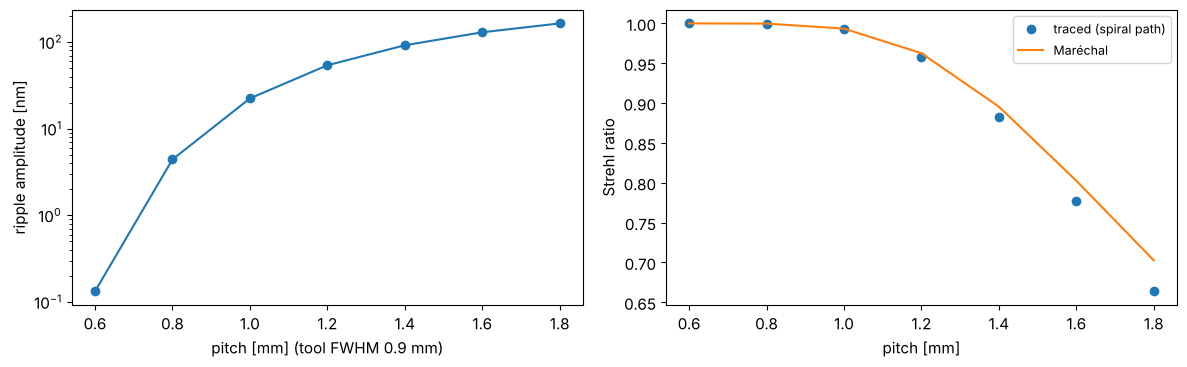

In [8]:
pitches = np.array([0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8])
amps = po.ripple_amplitude(pitches, W_TOOL, REMOVAL)
st = [polished(po.tool_path_ripple(XG, YG, p, W_TOOL, REMOVAL, path="spiral")).strehl(0.0, N=N_PUPIL)
      for p in pitches]
marechal = np.exp(-(2*pi*(N_BK7 - 1)*amps/np.sqrt(2)/WL)**2)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].semilogy(pitches, 1e6*amps, "o-")
axes[0].set_xlabel("pitch [mm] (tool FWHM {} mm)".format(W_TOOL))
axes[0].set_ylabel("ripple amplitude [nm]")
axes[1].plot(pitches, st, "o", label="traced (spiral path)")
axes[1].plot(pitches, marechal, "-", label="Maréchal")
axes[1].set_xlabel("pitch [mm]")
axes[1].set_ylabel("Strehl ratio")
axes[1].legend(fontsize=9)
plt.tight_layout()

Between a pitch of 0.6 mm and 1.8 mm, two thirds and twice the tool
width, the ripple grows from 0.1 nm to 160 nm and the Strehl ratio drops
from 1.000 to 0.67. Maréchal's estimate holds as long as the Strehl ratio
is above 0.9 and is optimistic beyond (a ripple of 160 nm is a phase
amplitude of 0.8 rad, where the small-phase estimate fails). Polishers
therefore keep the pitch well below the tool width, smooth with a larger
tool afterwards, or break the periodicity with pseudo-random paths that
spread the ripple into a broad, weak halo (Dunn and Walker).

## 5. A realistic part

A polished asphere has all of it at once. The map below is put together
as a shop would leave it after corrective polishing:

- **figure**: 25 nm of astigmatism (Fringe $Z_5$, from blocking or the
  mount) and a random low frequency error with a $f^{-2.5}$ PSD, 12 nm
  RMS;
- **MSF**: the spiral ripple of section 4 (1 mm pitch), plus random MSF
  between 0.5 and 4 cycles/mm, 2 nm RMS;
- **edge**: 100 nm turned down from 11 mm to the rim.

The PSD of the map (`polishing.radial_psd()`) shows the bands as a
specification by PSD (ISO 10110-8) would; a fit of 36 Fringe Zernikes
(`polishing.remove_zernikes()`), the usual first step with a measured map,
splits off the figure. Maréchal's estimate from the total RMS
wavefront is compared with the traced Strehl ratio.

RMS inside the aperture: total 30.4 nm; figure 15.9, MSF 15.9, edge 20.2 nm; after removing 36 Zernikes 17.9 nm


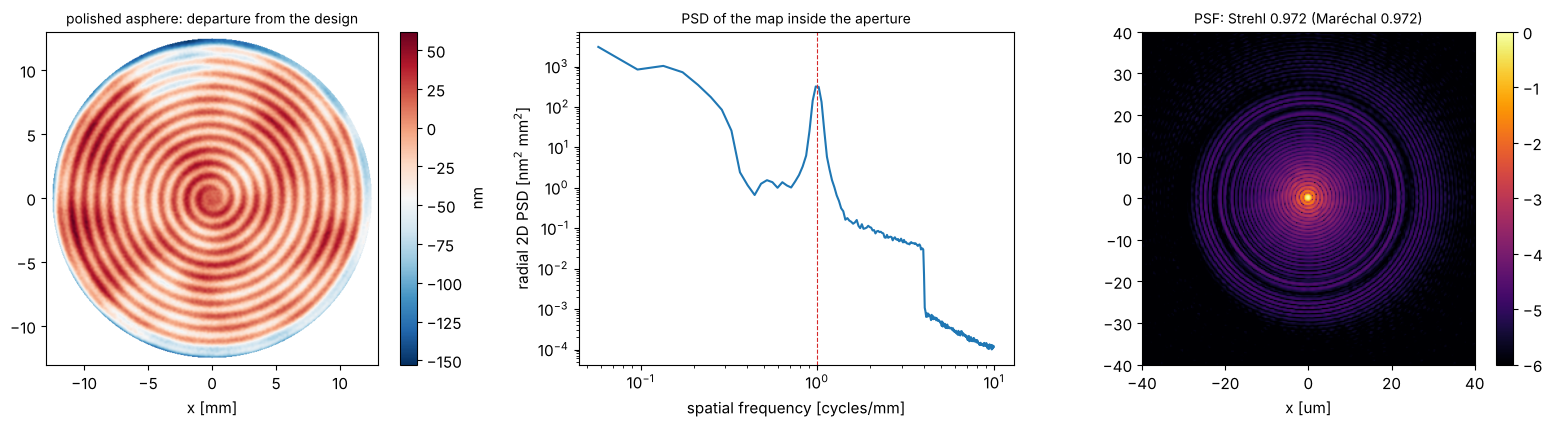

In [9]:
rng_seed = 11
figure_err = (po.random_surface(xg, xg, psd_figure, rms=12e-6, seed=rng_seed)
              + 25e-6*((XG/A)**2 - (YG/A)**2))
msf = spiral + po.random_surface(xg, xg, lambda f: po.psd_power_law(f, 1.0, 1.5, 0.5, 4.0),
                                 rms=2e-6, seed=rng_seed + 1)
edge = po.turned_down_edge(XG, YG, 11.0, A, 0.1e-3)
part = figure_err + msf + edge
S_part = polished(part)
I_part = psf(S_part)

inside = RG <= A
f_psd, P_psd = po.radial_psd(xg, xg, np.where(inside, part, np.nan))
residual, zc = po.remove_zernikes(XG, YG, part, A, n_terms=36)
rms_in = lambda z: np.sqrt(np.mean((z[inside] - z[inside].mean())**2))
sigma_w = S_part.rms_opd(0.0, N=N_PUPIL)
strehl_part = S_part.strehl(0.0, N=N_PUPIL)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
im = axes[0].imshow(1e6*np.where(inside, part, np.nan), extent=[xg[0], xg[-1], xg[0], xg[-1]],
                    origin="lower", cmap="RdBu_r")
plt.colorbar(im, ax=axes[0], label="nm")
axes[0].set_title("polished asphere: departure from the design", fontsize=10)
axes[0].set_xlabel("x [mm]")
axes[1].loglog(f_psd[1:], 1e12*P_psd[1:])
axes[1].axvline(1/P_TOOL, color="C3", lw=0.8, ls="--")
axes[1].set_xlabel("spatial frequency [cycles/mm]")
axes[1].set_ylabel("radial 2D PSD [nm$^2$ mm$^2$]")
axes[1].set_title("PSD of the map inside the aperture", fontsize=10)
im = show_psf(axes[2], I_part, "PSF: Strehl {:.3f} (Maréchal {:.3f})".format(
    strehl_part, np.exp(-(2*pi*sigma_w)**2)))
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
print("RMS inside the aperture: total {:.1f} nm; figure {:.1f}, MSF {:.1f}, edge {:.1f} nm; "
      "after removing 36 Zernikes {:.1f} nm".format(
          1e6*rms_in(part), 1e6*rms_in(figure_err), 1e6*rms_in(msf), 1e6*rms_in(edge),
          1e6*np.nanstd(residual)))

The map has 30 nm RMS inside the aperture, made of 16 nm figure, 16 nm
MSF (almost all of it the spiral ripple, the peak at 1 cycle/mm in the PSD)
and 20 nm from the edge. Removing 36 Zernikes takes out the astigmatism and
the low order random figure, but leaves 18 nm: the edge and the MSF are
beyond any reasonable Zernike set, which is why a polished part is
specified by its PSD or by band limited RMS values, not by Zernikes alone.
The traced Strehl ratio, 0.972, agrees with Maréchal's estimate from the
RMS wavefront. The PSF shows the three contributions separately: the core
is slightly blurred by the figure, the edge adds light to the first rings,
and the spiral ripple puts a ring at 19 um.

## 6. Energy maps: roughness, digs and scratches

Roughness takes power out of the image instead of shaping it. For a
Gaussian surface with RMS height $\sigma$ the specular part keeps the
fraction $e^{-(2\pi\sigma\,\Delta/\lambda)^2}$ with
$\Delta = |n_1\cos\theta_1 - n_2\cos\theta_2|$ for a refraction and
$2n\cos\theta$ for a reflection (Bennett and Mattsson); the rest is the
total integrated scatter (TIS), which leaves the sequential trace
(`polishing.specular_fraction()`). Well polished glass has 0.5 to 1 nm;
in transmission that costs a few $10^{-5}$, nothing. A zone that was not
polished out is a different matter: here the outer 1 mm of the asphere
kept a grey, fine ground texture of 30 nm RMS.

The flat face carries cosmetic defects, given as a pixelated map
(`polishing.defect_map()`, `kind="nearest"`): two digs of 0.5 and 0.3 mm
and a scratch of 15 mm length and 50 um width, opaque in this model
(MIL-PRF-13830B and ISO 10110-7 grade them by size).

Both are `SurfaceMap`s of the transmitted power fraction, set as
``energy_map`` of their surfaces. They do not change the rays; `ray_power()`
multiplies them along every ray, and `pupil()` turns the product into the
pupil amplitude $\sqrt{T}$ of the PSF.

mean transmitted power fraction 0.9943, peak 0.9920 of nominal


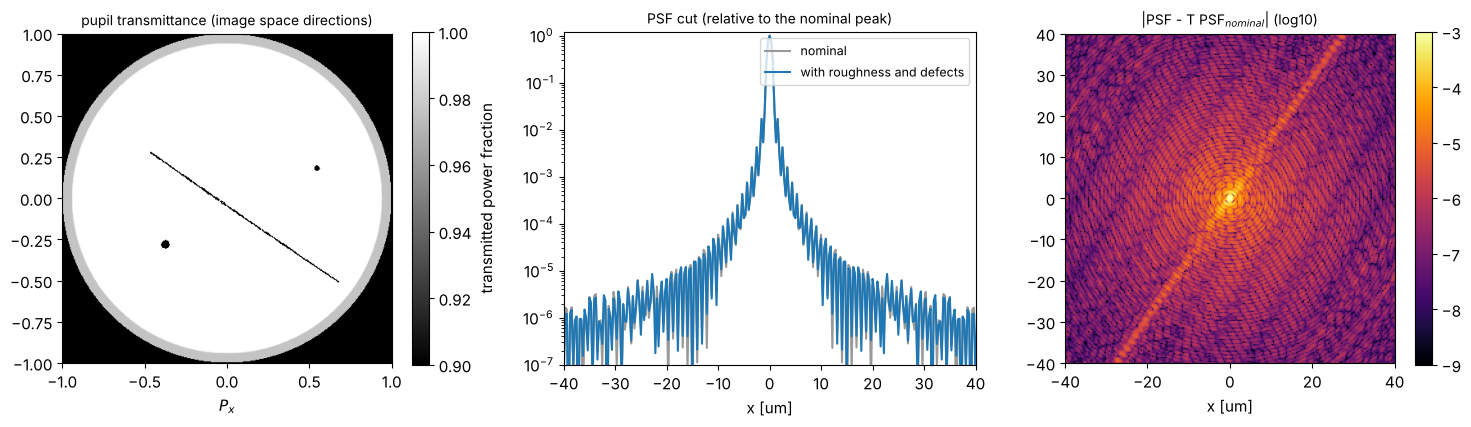

In [10]:
rough = np.where(RG > A - 1.0, 30e-6, 0.8e-6)          # RMS roughness [mm]
T_rough = po.specular_fraction(rough, WL, n1=N_BK7, n2=1.0)
x1 = np.linspace(-13, 13, 1041)                          # 25 um pixels
X1, Y1 = np.meshgrid(x1, x1)
T_defects = po.defect_map(X1, Y1, digs=[(4.0, 3.0, 0.5), (-6.0, -2.0, 0.3)],
                          scratches=[(-8.0, 6.0, 5.0, -3.0, 0.05)])
energy = {0: SurfaceMap(x1, x1, T_defects, kind="nearest", outside=1.0),
          1: SurfaceMap(xg, xg, T_rough, kind="linear", outside=1.0)}
S_energy = polished(energy=energy)
I_energy = np.abs(S_energy.psf(xi, xi, 0.0, N=401, normalization=None))**2
I_ref = np.abs(lens.psf(xi, xi, 0.0, N=401, normalization=None))**2

px = np.linspace(-1, 1, 401)
PX, PY = np.meshgrid(px, px)
pupil = S_energy.pupil(0.0, N=401)
amp_pupil = pupil.mask(PX, PY)
bundle = S_energy.trace_pupil(0.0, PX[PX**2 + PY**2 <= 1], PY[PX**2 + PY**2 <= 1])
T_mean = np.nanmean(S_energy.ray_power(bundle)[-1])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
im = axes[0].imshow(amp_pupil**2, extent=[-1, 1, -1, 1], origin="lower", cmap="gray", vmin=0.9, vmax=1)
plt.colorbar(im, ax=axes[0], label="transmitted power fraction")
axes[0].set_title("pupil transmittance (image space directions)", fontsize=10)
axes[0].set_xlabel("$P_x$")
c = len(xi)//2
axes[1].semilogy(1e3*xi, I_ref[c]/I_ref.max(), color="0.6", label="nominal")
axes[1].semilogy(1e3*xi, I_energy[c]/I_ref.max(), label="with roughness and defects")
axes[1].set_xlim(-40, 40)
axes[1].set_ylim(1e-7, 1.2)
axes[1].set_xlabel("x [um]")
axes[1].legend(fontsize=9)
axes[1].set_title("PSF cut (relative to the nominal peak)", fontsize=10)
im = show_psf(axes[2], np.abs(I_energy - I_ref*T_mean)/I_ref.max(),
              "|PSF - T PSF$_{nominal}$| (log10)", vmin=-9, vmax=-3)
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
print("mean transmitted power fraction {:.4f}, peak {:.4f} of nominal".format(
    T_mean, I_energy.max()/I_ref.max()))

The pupil (here in image space directions, point-mirrored with respect to
the lens) shows the grey rim, which passes 97.7 % (30 nm RMS give a TIS of
2.3 % in transmission), and the defects as black pixels. In total the
lens passes 99.4 % of the power into the image, and the peak of the PSF is
99.2 % of the nominal one. The peak drops faster than the power: in the
scalar picture an opaque defect of the
area fraction $\varepsilon$ removes $\varepsilon$ of the power but
lowers the peak by $2\varepsilon$, because by Babinet's principle it
also diffracts the power $\varepsilon$ out of the image. Where that light
goes is visible in the difference to the scaled nominal PSF: the scratch,
50 um wide and 15 mm long, diffracts into a long streak perpendicular to
it, the small digs into faint, wide disks below the plotted range. The
roughness of the rim scatters into angles far beyond this window and
enters only as the loss.

Energy maps are not limited to polishing: a coating non-uniformity, the
transmittance map of a filter measured with a camera, dust or a soft
aperture are the same kind of map. On a mirror the map is the
reflectance. `trace_polarization()` includes them in its matrices, so the
transmittance and the vectorial PSF see them as well.

## Summary

- A `SurfaceMap` turns pixels into a smooth, differentiable surface;
  `MapSurface` puts it on top of any base surface (and of Zernike terms),
  and the rays are refracted by the slopes of the interpolant. Use cubic
  splines for sags: bilinear maps are faceted and send the rays astray.
- Energy maps (``energy_map`` of any surface) carry the transmitted or
  reflected power fraction; they apodize the pupil of `psf()` and `mtf()`
  and enter `ray_power()` and `trace_polarization()`.
- A turned-down edge acts on the outer zone with its large share of the
  pupil area; a reduced clear aperture removes it.
- Sub-aperture tools leave a ripple that depends exponentially on the
  ratio of tool width to pitch. It hardly changes the Strehl ratio, but it
  puts ghosts or rings at $f\lambda/p$ with the power $\beta^2/4$ each, and
  lowers the MTF by $\beta^2/2$ at almost all frequencies.
- Zernikes describe the figure; for MSF and edge errors a polished surface
  needs a PSD or band limited specification, and a gridded map in the
  ray trace.
- Roughness and defects are losses: a few $10^{-5}$ for good polish in
  transmission, a percent for a grey zone, and Babinet's twice the area
  fraction of a dig or scratch at the peak of the PSF.

### References

F. W. Preston, "The theory and design of plate glass polishing machines",
J. Soc. Glass Technol. 11, 214-256 (1927).

D. M. Aikens, C. R. Wolfe and J. K. Lawson, "Use of power spectral density
(PSD) functions in specifying optics for the National Ignition Facility",
Proc. SPIE 2576, 281-292 (1995).

R. N. Youngworth and B. D. Stone, "Simple estimates for the effects of
mid-spatial-frequency surface errors on image quality", Appl. Opt. 39,
2198-2209 (2000).

J. M. Tamkin and T. D. Milster, "Effects of structured mid-spatial
frequency surface errors on image performance", Appl. Opt. 49, 6522-6536
(2010).

D. W. Kim, W. H. Park, S.-W. Kim and J. H. Burge, "Parametric modeling of
edge effects for polishing tool influence functions", Opt. Express 17,
5656-5665 (2009).

D. D. Walker et al., "The 'Precessions' tooling for polishing and figuring
flat, spherical and aspheric surfaces", Opt. Express 11, 958-964 (2003).

C. R. Dunn and D. D. Walker, "Pseudo-random tool paths for CNC sub-aperture
polishing and other applications", Opt. Express 16, 18942-18949 (2008).

E. L. Church, "Fractal surface finish", Appl. Opt. 27, 1518-1526 (1988).

J. M. Bennett and L. Mattsson, "Introduction to Surface Roughness and
Scattering", 2nd ed., Optical Society of America (1999).

G. W. Forbes, "Never-ending struggles with mid-spatial frequencies",
Proc. SPIE 9525, 95251B (2015).

ISO 10110-5 (surface form tolerances), ISO 10110-7 (surface imperfections),
ISO 10110-8 (surface texture).

In [11]:
print("run time {:.0f} s".format(time.time() - T_START))

run time 35 s
